In [ ]:
# ============================================================
# AUTOSOC - STEP 1
# ML-BASED THREAT DETECTION
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# PATH
# ------------------------------------------------------------

BASE_PATH = "/content/drive/MyDrive/AutoSOC_Project"

TRAIN_FILE = os.path.join(
    BASE_PATH,
    "train_test_network.csv"
)

# ------------------------------------------------------------
# FEATURES
# ------------------------------------------------------------

FEATURES = [
    "src_port",
    "dst_port",
    "duration",
    "src_bytes",
    "dst_bytes",
    "missed_bytes",
    "src_pkts",
    "src_ip_bytes",
    "dst_pkts",
    "dst_ip_bytes",
    "dns_qclass",
    "dns_qtype",
    "dns_rcode",
    "http_request_body_len",
    "http_response_body_len",
    "http_status_code"
]

print("=" * 75)
print("STEP 1: ML-BASED THREAT DETECTION")
print("=" * 75)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

df = pd.read_csv(
    TRAIN_FILE,
    low_memory=False
)

print("\nOriginal dataset shape:")
print(df.shape)

# ------------------------------------------------------------
# REMOVE EXACT DUPLICATES
# ------------------------------------------------------------

before = len(df)

df = (
    df
    .drop_duplicates()
    .reset_index(drop=True)
)

after = len(df)

print("\nExact duplicate rows removed:")
print(before - after)

print("\nDataset after duplicate removal:")
print(df.shape)

# ------------------------------------------------------------
# CLEAN TARGET
# ------------------------------------------------------------

df["type"] = (
    df["type"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print("\nAttack class distribution:")
print(df["type"].value_counts())

# ------------------------------------------------------------
# X AND y
# ------------------------------------------------------------

X = df[FEATURES].copy()

for col in FEATURES:
    X[col] = pd.to_numeric(
        X[col],
        errors="coerce"
    )

X = X.fillna(0)

y = df["type"].copy()

# ------------------------------------------------------------
# SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

threat_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

threat_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

y_pred = threat_model.predict(
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nHeld-out Test Accuracy:")
print(
    round(test_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

prediction_example = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

prediction_example["Correct"] = (
    prediction_example["Actual"]
    ==
    prediction_example["Predicted"]
)

print("\nExample predictions:")

display(
    prediction_example
)

print("\nSTEP 1 COMPLETE ✅")

Mounted at /content/drive
STEP 1: ML-BASED THREAT DETECTION

Original dataset shape:
(211043, 44)

Exact duplicate rows removed:
20569

Dataset after duplicate removal:
(190474, 44)

Attack class distribution:
type
normal        42040
scanning      20000
ddos          19993
injection     19964
password      19861
dos           18992
backdoor      18711
xss           15137
ransomware    14735
mitm           1041
Name: count, dtype: int64

Training samples: 152379
Testing samples : 38095

Held-out Test Accuracy:
98.74 %

Classification Report:

              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      3742
        ddos       0.99      0.98      0.98      3999
         dos       0.99      0.98      0.99      3799
   injection       0.98      0.97      0.97      3993
        mitm       0.76      0.83      0.79       208
      normal       1.00      1.00      1.00      8408
    password       1.00      0.99      0.99      3972
  ransomware      

,Actual,Predicted,Correct
0,password,password,True
1,normal,normal,True
2,password,password,True
3,normal,normal,True
4,normal,normal,True
5,scanning,scanning,True
6,scanning,scanning,True
7,normal,normal,True
8,ddos,ddos,True
9,ransomware,ransomware,True



STEP 1 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - STEP 2
# AUTONOMOUS TIMESTAMPED THREAT DETECTION
# ============================================================

NETWORK_FILES = [
    1,
    9,
    16,
    18
]

CONFIDENCE_THRESHOLD = 0.80

event_parts = []

LABELS = list(
    threat_model.classes_
)

cm_total = np.zeros(
    (
        len(LABELS),
        len(LABELS)
    ),
    dtype=np.int64
)

total_external_events = 0
total_external_correct = 0

high_conf_total = 0
high_conf_correct = 0

print("=" * 75)
print("STEP 2: AUTONOMOUS TIMESTAMPED THREAT DETECTION")
print("=" * 75)

print(
    "\nConfidence threshold:",
    CONFIDENCE_THRESHOLD
)

for file_id in NETWORK_FILES:

    path = os.path.join(
        BASE_PATH,
        f"Network_dataset_{file_id}.csv"
    )

    print(
        f"\nProcessing Network_dataset_{file_id}.csv"
    )

    # --------------------------------------------------------
    # CHECK COLUMNS
    # --------------------------------------------------------

    available_columns = pd.read_csv(
        path,
        nrows=0
    ).columns.tolist()

    required = [
        "ts",
        "src_ip",
        "dst_ip",
        "type"
    ] + FEATURES

    missing = [
        col
        for col in required
        if col not in available_columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns in Network_dataset_{file_id}: "
            f"{missing}"
        )

    # --------------------------------------------------------
    # CHUNK PROCESSING
    # --------------------------------------------------------

    chunks = pd.read_csv(
        path,
        usecols=required,
        chunksize=200000,
        low_memory=False
    )

    file_forwarded = 0

    for chunk in chunks:

        chunk = chunk.reset_index(
            drop=True
        )

        # ------------------------------------------
        # FEATURES
        # ------------------------------------------

        for col in FEATURES:

            chunk[col] = pd.to_numeric(
                chunk[col],
                errors="coerce"
            )

        chunk[FEATURES] = (
            chunk[FEATURES]
            .fillna(0)
        )

        # ------------------------------------------
        # MODEL PREDICTION
        # ------------------------------------------

        predictions = threat_model.predict(
            chunk[FEATURES]
        )

        probabilities = threat_model.predict_proba(
            chunk[FEATURES]
        )

        confidence = probabilities.max(
            axis=1
        )

        predictions = (
            pd.Series(predictions)
            .astype(str)
            .str.lower()
            .str.strip()
            .to_numpy()
        )

        # ------------------------------------------
        # ACTUAL LABEL
        # ONLY FOR EVALUATION
        # ------------------------------------------

        actual = (
            chunk["type"]
            .astype(str)
            .str.lower()
            .str.strip()
            .to_numpy()
        )

        valid_eval = np.isin(
            actual,
            LABELS
        )

        actual_eval = actual[
            valid_eval
        ]

        pred_eval = predictions[
            valid_eval
        ]

        conf_eval = confidence[
            valid_eval
        ]

        # ------------------------------------------
        # EXTERNAL CONFUSION MATRIX
        # ------------------------------------------

        cm_total += confusion_matrix(
            actual_eval,
            pred_eval,
            labels=LABELS
        )

        total_external_events += len(
            actual_eval
        )

        total_external_correct += (
            actual_eval
            ==
            pred_eval
        ).sum()

        # ------------------------------------------
        # HIGH CONFIDENCE EVALUATION
        # ------------------------------------------

        high_mask = (
            conf_eval
            >=
            CONFIDENCE_THRESHOLD
        )

        high_conf_total += (
            high_mask.sum()
        )

        high_conf_correct += (
            actual_eval[high_mask]
            ==
            pred_eval[high_mask]
        ).sum()

        # ------------------------------------------
        # AUTONOMOUS FILTER
        #
        # NO GROUND TRUTH USED HERE
        # ------------------------------------------

        autonomous_mask = (
            (predictions != "normal")
            &
            (
                confidence
                >=
                CONFIDENCE_THRESHOLD
            )
        )

        temp = pd.DataFrame({

            "ts":
                pd.to_numeric(
                    chunk.loc[
                        autonomous_mask,
                        "ts"
                    ],
                    errors="coerce"
                ).to_numpy(),

            "src_ip":
                chunk.loc[
                    autonomous_mask,
                    "src_ip"
                ]
                .astype(str)
                .str.strip()
                .to_numpy(),

            "dst_ip":
                chunk.loc[
                    autonomous_mask,
                    "dst_ip"
                ]
                .astype(str)
                .str.strip()
                .to_numpy(),

            "predicted_type":
                predictions[
                    autonomous_mask
                ],

            "confidence":
                confidence[
                    autonomous_mask
                ],

            "source_file":
                file_id
        })

        temp = temp.dropna(
            subset=[
                "ts",
                "src_ip",
                "dst_ip",
                "predicted_type",
                "confidence"
            ]
        )

        event_parts.append(
            temp
        )

        file_forwarded += len(
            temp
        )

        del chunk
        del temp

        gc.collect()

    print(
        "High-confidence malicious events forwarded:",
        file_forwarded
    )

# ------------------------------------------------------------
# COMBINE DETECTIONS
# ------------------------------------------------------------

detected_events = pd.concat(
    event_parts,
    ignore_index=True
)

del event_parts
gc.collect()

detected_events = (
    detected_events
    .dropna(
        subset=[
            "ts",
            "src_ip",
            "dst_ip",
            "predicted_type",
            "confidence"
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# EXTERNAL METRICS
# ------------------------------------------------------------

external_accuracy = (
    total_external_correct
    /
    total_external_events
) if total_external_events else 0

high_conf_accuracy = (
    high_conf_correct
    /
    high_conf_total
) if high_conf_total else 0

high_conf_coverage = (
    high_conf_total
    /
    total_external_events
) if total_external_events else 0

print("\n" + "=" * 75)

print(
    "External timestamped events evaluated:",
    total_external_events
)

print(
    "Overall external prediction agreement:",
    round(
        external_accuracy * 100,
        2
    ),
    "%"
)

print(
    "High-confidence prediction agreement:",
    round(
        high_conf_accuracy * 100,
        2
    ),
    "%"
)

print(
    "High-confidence coverage:",
    round(
        high_conf_coverage * 100,
        2
    ),
    "%"
)

print(
    "\nHigh-confidence predicted malicious events "
    "sent to correlation:",
    len(detected_events)
)

print("\nPredicted attack distribution:")

print(
    detected_events[
        "predicted_type"
    ].value_counts()
)

# ------------------------------------------------------------
# CLASS-WISE EXTERNAL METRICS
# ------------------------------------------------------------

tp = np.diag(
    cm_total
).astype(float)

support = cm_total.sum(
    axis=1
).astype(float)

predicted_count = cm_total.sum(
    axis=0
).astype(float)

precision = np.divide(
    tp,
    predicted_count,
    out=np.zeros_like(tp),
    where=predicted_count != 0
)

recall = np.divide(
    tp,
    support,
    out=np.zeros_like(tp),
    where=support != 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros_like(tp),
    where=(
        precision + recall
    ) != 0
)

external_report = pd.DataFrame({

    "Class":
        LABELS,

    "Precision":
        precision.round(3),

    "Recall":
        recall.round(3),

    "F1":
        f1.round(3),

    "Support":
        support.astype(int)
})

print(
    "\nExternal class-wise evaluation:"
)

display(
    external_report
)

print(
    "\nIMPORTANT:"
)

print(
    "Ground-truth labels were used only "
    "to evaluate model performance."
)

print(
    "They were NOT used to select events "
    "for attack correlation."
)

print("\nSTEP 2 COMPLETE ✅")

STEP 2: AUTONOMOUS TIMESTAMPED THREAT DETECTION

Confidence threshold: 0.8

Processing Network_dataset_1.csv
High-confidence malicious events forwarded: 135907

Processing Network_dataset_9.csv
High-confidence malicious events forwarded: 22740

Processing Network_dataset_16.csv
High-confidence malicious events forwarded: 602444

Processing Network_dataset_18.csv
High-confidence malicious events forwarded: 492084

External timestamped events evaluated: 3679768
Overall external prediction agreement: 56.3 %
High-confidence prediction agreement: 93.07 %
High-confidence coverage: 41.57 %

High-confidence predicted malicious events sent to correlation: 1253175

Predicted attack distribution:
predicted_type
ddos          862186
password      167131
scanning      123998
xss            72585
dos            22556
ransomware      2271
backdoor        1573
injection        735
mitm             140
Name: count, dtype: int64

External class-wise evaluation:


,Class,Precision,Recall,F1,Support
0,backdoor,0.000,0.000,0.000,0
1,ddos,0.986,0.793,0.879,1425202
2,dos,0.152,0.023,0.040,975261
3,injection,0.000,0.000,0.000,0
4,mitm,0.000,0.000,0.000,0
5,normal,0.394,0.954,0.558,281093
6,password,0.869,0.814,0.841,206891
7,ransomware,0.000,0.000,0.000,0
8,scanning,0.461,0.611,0.525,791321
9,xss,0.000,0.000,0.000,0



IMPORTANT:
Ground-truth labels were used only to evaluate model performance.
They were NOT used to select events for attack correlation.

STEP 2 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - STEP 3
# ATTACK CORRELATION + TEMPORAL REASONING
# ============================================================

print("=" * 75)
print("STEP 3: ATTACK CORRELATION AND TEMPORAL REASONING")
print("=" * 75)

# ------------------------------------------------------------
# ATTACK -> ANALYTICAL STAGE
# ------------------------------------------------------------

ATTACK_STAGE_MAP = {

    "scanning":
        "Reconnaissance",

    "xss":
        "Initial Access",

    "injection":
        "Initial Access",

    "password":
        "Credential Access",

    "mitm":
        "Credential/Network Access",

    "backdoor":
        "Persistence",

    "ransomware":
        "Impact",

    "dos":
        "Impact",

    "ddos":
        "Impact"
}

# ------------------------------------------------------------
# APPROXIMATE FORWARD STAGE ORDER
# ------------------------------------------------------------

STAGE_ORDER = {

    "Reconnaissance": 1,

    "Initial Access": 2,

    "Credential Access": 3,

    "Credential/Network Access": 4,

    "Persistence": 5,

    "Impact": 6
}

# ------------------------------------------------------------
# 30-MINUTE INACTIVITY THRESHOLD
# ------------------------------------------------------------

CAMPAIGN_WINDOW = 1800

events = detected_events[
    [
        "ts",
        "src_ip",
        "dst_ip",
        "predicted_type",
        "confidence"
    ]
].copy()

events = events.rename(
    columns={
        "predicted_type":
            "attack_type"
    }
)

# ------------------------------------------------------------
# CLEAN
# ------------------------------------------------------------

events["ts"] = pd.to_numeric(
    events["ts"],
    errors="coerce"
)

events["confidence"] = pd.to_numeric(
    events["confidence"],
    errors="coerce"
)

events["src_ip"] = (
    events["src_ip"]
    .astype(str)
    .str.strip()
)

events["dst_ip"] = (
    events["dst_ip"]
    .astype(str)
    .str.strip()
)

events["attack_type"] = (
    events["attack_type"]
    .astype(str)
    .str.lower()
    .str.strip()
)

events = events.dropna(
    subset=[
        "ts",
        "confidence"
    ]
)

invalid_values = {
    "",
    "nan",
    "none",
    "-"
}

events = events[
    ~events[
        "src_ip"
    ]
    .str.lower()
    .isin(
        invalid_values
    )
].copy()

events = events[
    ~events[
        "dst_ip"
    ]
    .str.lower()
    .isin(
        invalid_values
    )
].copy()

# ------------------------------------------------------------
# STAGE
# ------------------------------------------------------------

events["attack_stage"] = (
    events[
        "attack_type"
    ]
    .map(
        ATTACK_STAGE_MAP
    )
)

events = (
    events
    .dropna(
        subset=[
            "attack_stage"
        ]
    )
    .reset_index(drop=True)
)

print(
    "\nHigh-confidence malicious events entering correlation:",
    len(events)
)

# ------------------------------------------------------------
# SORT
# ------------------------------------------------------------

events = (
    events
    .sort_values(
        [
            "src_ip",
            "dst_ip",
            "ts"
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# TIME GAP
# ------------------------------------------------------------

events["time_gap"] = (
    events
    .groupby(
        [
            "src_ip",
            "dst_ip"
        ]
    )["ts"]
    .diff()
)

# ------------------------------------------------------------
# SESSION / CAMPAIGN
# ------------------------------------------------------------

events["new_campaign"] = (
    events[
        "time_gap"
    ].isna()
    |
    (
        events[
            "time_gap"
        ]
        >
        CAMPAIGN_WINDOW
    )
)

events["campaign_id"] = (
    events
    .groupby(
        [
            "src_ip",
            "dst_ip"
        ]
    )[
        "new_campaign"
    ]
    .cumsum()
)

# ============================================================
# HELPERS
# ============================================================

def collapse_consecutive(series):

    result = []
    previous = None

    for item in series:

        if pd.isna(item):
            continue

        item = str(
            item
        ).strip()

        if item != previous:

            result.append(
                item
            )

        previous = item

    return result


def attack_sequence(series):

    return " → ".join(
        collapse_consecutive(
            series
        )
    )


def stage_sequence(series):

    return " → ".join(
        collapse_consecutive(
            series
        )
    )


def valid_stage_progression(
    stage_sequence_text
):

    if not isinstance(
        stage_sequence_text,
        str
    ):
        return False

    stages = [
        x.strip()
        for x in
        stage_sequence_text.split("→")
        if x.strip()
    ]

    # At least 2 stages
    if len(stages) < 2:
        return False

    # At least 2 different stages
    if len(set(stages)) < 2:
        return False

    orders = [
        STAGE_ORDER.get(
            stage
        )
        for stage in stages
    ]

    if any(
        value is None
        for value in orders
    ):
        return False

    # STRICT FORWARD MOVEMENT
    return all(
        orders[i]
        <
        orders[i + 1]

        for i in range(
            len(orders) - 1
        )
    )

# ------------------------------------------------------------
# CAMPAIGN AGGREGATION
# ------------------------------------------------------------

campaigns = (
    events
    .groupby(
        [
            "src_ip",
            "dst_ip",
            "campaign_id"
        ]
    )
    .agg(

        start_time=(
            "ts",
            "min"
        ),

        end_time=(
            "ts",
            "max"
        ),

        total_events=(
            "ts",
            "size"
        ),

        attack_type_count=(
            "attack_type",
            "nunique"
        ),

        attack_sequence=(
            "attack_type",
            attack_sequence
        ),

        stage_count=(
            "attack_stage",
            "nunique"
        ),

        stage_sequence=(
            "attack_stage",
            stage_sequence
        ),

        mean_confidence=(
            "confidence",
            "mean"
        ),

        min_confidence=(
            "confidence",
            "min"
        ),

        max_confidence=(
            "confidence",
            "max"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# DATETIME
# ------------------------------------------------------------

campaigns[
    "start_datetime"
] = pd.to_datetime(
    campaigns[
        "start_time"
    ],
    unit="s"
)

campaigns[
    "end_datetime"
] = pd.to_datetime(
    campaigns[
        "end_time"
    ],
    unit="s"
)

campaigns[
    "duration_minutes"
] = (
    (
        campaigns[
            "end_time"
        ]
        -
        campaigns[
            "start_time"
        ]
    )
    /
    60
).round(2)

campaigns[
    "mean_confidence"
] = campaigns[
    "mean_confidence"
].round(3)

campaigns[
    "min_confidence"
] = campaigns[
    "min_confidence"
].round(3)

campaigns[
    "max_confidence"
] = campaigns[
    "max_confidence"
].round(3)

# ------------------------------------------------------------
# VALID STAGE PROGRESSION
# ------------------------------------------------------------

campaigns[
    "valid_stage_progression"
] = (
    campaigns[
        "stage_sequence"
    ]
    .apply(
        valid_stage_progression
    )
)

# ------------------------------------------------------------
# CAMPAIGN TYPE
# ------------------------------------------------------------

def classify_campaign(row):

    if (
        row[
            "stage_count"
        ]
        >=
        2
        and
        row[
            "valid_stage_progression"
        ]
    ):

        return (
            "Candidate Multi-stage"
        )

    elif (
        row[
            "attack_type_count"
        ]
        >=
        2
    ):

        return (
            "Correlated Multi-alert "
            "(Non-progressive)"
        )

    else:

        return (
            "Single-stage"
        )


campaigns[
    "campaign_type"
] = campaigns.apply(
    classify_campaign,
    axis=1
)

# ------------------------------------------------------------
# TIMELINE EVIDENCE
# ------------------------------------------------------------

events[
    "previous_attack"
] = (
    events
    .groupby(
        [
            "src_ip",
            "dst_ip",
            "campaign_id"
        ]
    )[
        "attack_type"
    ]
    .shift()
)

transition_events = events[
    events[
        "previous_attack"
    ].isna()
    |
    (
        events[
            "attack_type"
        ]
        !=
        events[
            "previous_attack"
        ]
    )
].copy()

transition_events = (
    transition_events
    .sort_values(
        [
            "src_ip",
            "dst_ip",
            "campaign_id",
            "ts"
        ]
    )
)


def build_transition_timeline(
    group,
    max_transitions=20
):

    group = group.sort_values(
        "ts"
    )

    parts = []

    for _, row in (
        group
        .head(
            max_transitions
        )
        .iterrows()
    ):

        dt = pd.to_datetime(
            row[
                "ts"
            ],
            unit="s"
        )

        parts.append(
            f"{dt} : "
            f"{row['attack_type']} "
            f"({row['attack_stage']})"
        )

    if len(group) > max_transitions:

        parts.append(
            f"... +"
            f"{len(group) - max_transitions} "
            f"additional transitions"
        )

    return " | ".join(
        parts
    )


timeline_table = (
    transition_events
    .groupby(
        [
            "src_ip",
            "dst_ip",
            "campaign_id"
        ]
    )
    .apply(
        build_transition_timeline
    )
    .reset_index(
        name=
        "timeline_evidence"
    )
)

campaigns = campaigns.merge(
    timeline_table,

    on=[
        "src_ip",
        "dst_ip",
        "campaign_id"
    ],

    how="left"
)

# ------------------------------------------------------------
# CORRELATION EVIDENCE
# ------------------------------------------------------------

campaigns[
    "correlation_evidence"
] = campaigns.apply(

    lambda row:

    (
        f"Same source={row['src_ip']}; "
        f"same target={row['dst_ip']}; "
        f"30-minute inactivity threshold; "
        f"campaign duration="
        f"{row['duration_minutes']} minutes; "
        f"events={row['total_events']}; "
        f"mean confidence="
        f"{row['mean_confidence']}; "
        f"stages="
        f"{row['stage_sequence']}; "
        f"forward progression="
        f"{row['valid_stage_progression']}."
    ),

    axis=1
)

# ------------------------------------------------------------
# SORT
# ------------------------------------------------------------

campaigns = (
    campaigns
    .sort_values(
        [
            "valid_stage_progression",
            "stage_count",
            "total_events",
            "mean_confidence"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

total_campaigns = len(
    campaigns
)

candidate_multi_stage = (
    campaigns[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"
).sum()

non_progressive = (
    campaigns[
        "campaign_type"
    ]
    ==
    "Correlated Multi-alert (Non-progressive)"
).sum()

single_stage = (
    campaigns[
        "campaign_type"
    ]
    ==
    "Single-stage"
).sum()

print(
    "\nTotal correlated campaigns:",
    total_campaigns
)

print(
    "Valid candidate multi-stage campaigns:",
    candidate_multi_stage
)

print(
    "Non-progressive multi-alert campaigns:",
    non_progressive
)

print(
    "Single-stage campaigns:",
    single_stage
)

# ------------------------------------------------------------
# ALERT REDUCTION
# ------------------------------------------------------------

raw_alerts = len(
    events
)

alert_reduction = (
    (
        1
        -
        total_campaigns
        /
        raw_alerts
    )
    *
    100
) if raw_alerts else 0

print(
    "\nHigh-confidence malicious event alerts:",
    raw_alerts
)

print(
    "Correlated campaign alerts:",
    total_campaigns
)

print(
    "Alert reduction after correlation:",
    round(
        alert_reduction,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# MULTI-STAGE
# ------------------------------------------------------------

multi_stage_campaigns = campaigns[
    campaigns[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"
].copy()

print(
    "\nValid Candidate Multi-stage Campaigns:",
    len(
        multi_stage_campaigns
    )
)

if len(
    multi_stage_campaigns
) > 0:

    display(
        multi_stage_campaigns[
            [
                "src_ip",
                "dst_ip",
                "start_datetime",
                "end_datetime",
                "duration_minutes",
                "attack_sequence",
                "stage_sequence",
                "timeline_evidence",
                "mean_confidence",
                "correlation_evidence"
            ]
        ]
    )

else:

    print(
        "No valid candidate multi-stage "
        "campaign was found."
    )

# ------------------------------------------------------------
# REJECTED MULTI-ALERTS
# ------------------------------------------------------------

invalid_multi_alerts = campaigns[
    (
        campaigns[
            "attack_type_count"
        ]
        >=
        2
    )
    &
    (
        campaigns[
            "valid_stage_progression"
        ]
        ==
        False
    )
].copy()

print(
    "\nRejected non-progressive multi-alert campaigns:",
    len(
        invalid_multi_alerts
    )
)

print("\nSTEP 3 COMPLETE ✅")

STEP 3: ATTACK CORRELATION AND TEMPORAL REASONING

High-confidence malicious events entering correlation: 1253175

Total correlated campaigns: 3330
Valid candidate multi-stage campaigns: 2
Non-progressive multi-alert campaigns: 522
Single-stage campaigns: 2806

High-confidence malicious event alerts: 1253175
Correlated campaign alerts: 3330
Alert reduction after correlation: 99.73 %

Valid Candidate Multi-stage Campaigns: 2


,src_ip,dst_ip,start_datetime,end_datetime,duration_minutes,attack_sequence,stage_sequence,timeline_evidence,mean_confidence,correlation_evidence
0,192.168.1.31,192.168.1.250,2019-04-23 12:10:10,2019-04-23 13:21:42,71.53,scanning → xss → password,Reconnaissance → Initial Access → Credential A...,2019-04-23 12:10:10 : scanning (Reconnaissance...,1.00,Same source=192.168.1.31; same target=192.168....
1,192.168.1.190,202.12.31.53,2019-04-26 07:03:56,2019-04-26 07:04:11,0.25,mitm → ddos,Credential/Network Access → Impact,2019-04-26 07:03:56 : mitm (Credential/Network...,0.97,Same source=192.168.1.190; same target=202.12....



Rejected non-progressive multi-alert campaigns: 522

STEP 3 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - STEP 4
# THREAT INTELLIGENCE
# RISK SCORING
# INCIDENT INVESTIGATION
# RESPONSE RECOMMENDATION
# ============================================================

print("=" * 75)
print("STEP 4: AUTOSOC INTELLIGENCE AND RESPONSE")
print("=" * 75)

# ------------------------------------------------------------
# PROTOTYPE SEVERITY
# ------------------------------------------------------------

SEVERITY_MAP = {

    "scanning": 10,
    "xss": 25,
    "password": 25,
    "injection": 30,
    "dos": 35,
    "ddos": 35,
    "mitm": 35,
    "backdoor": 40,
    "ransomware": 50
}

# ------------------------------------------------------------
# MITRE ATT&CK CONTEXT
# ------------------------------------------------------------

MITRE_MAP = {

    "scanning":
        "T1046 - Network Service Scanning",

    "password":
        "T1110 - Brute Force",

    "ddos":
        "T1498 - Network Denial of Service",

    "dos":
        "T1499 - Endpoint Denial of Service",

    "ransomware":
        "T1486 - Data Encrypted for Impact",

    "mitm":
        "T1557 - Adversary-in-the-Middle",

    "xss":
        "Web exploitation - exact MITRE technique "
        "requires additional context",

    "backdoor":
        "Backdoor/Persistence activity - exact MITRE "
        "technique requires additional context",

    "injection":
        "Injection activity - exact MITRE technique "
        "requires additional context"
}

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def split_attacks(sequence):

    return [
        item.strip()
        for item in
        sequence.split("→")
        if item.strip()
    ]


def base_severity(sequence):

    attacks = split_attacks(
        sequence
    )

    scores = [
        SEVERITY_MAP.get(
            attack,
            15
        )
        for attack in attacks
    ]

    return max(
        scores
    ) if scores else 0


def mitre_context(sequence):

    attacks = split_attacks(
        sequence
    )

    contexts = []

    for attack in attacks:

        contexts.append(
            MITRE_MAP.get(
                attack,
                "Exact MITRE technique "
                "requires additional context"
            )
        )

    return " | ".join(
        contexts
    )

# ------------------------------------------------------------
# BASE SEVERITY
# ------------------------------------------------------------

campaigns[
    "base_severity"
] = campaigns[
    "attack_sequence"
].apply(
    base_severity
)

# ------------------------------------------------------------
# EVENT VOLUME SCORE
# MAX = 20
# ------------------------------------------------------------

campaigns[
    "event_score"
] = (
    np.log10(
        campaigns[
            "total_events"
        ]
        +
        1
    )
    /
    6.0
    *
    20
).clip(
    0,
    20
).round(2)

# ------------------------------------------------------------
# CONFIDENCE SCORE
# MAX = 10
# ------------------------------------------------------------

campaigns[
    "confidence_score"
] = (
    campaigns[
        "mean_confidence"
    ]
    *
    10
).clip(
    0,
    10
).round(2)

# ------------------------------------------------------------
# VALID MULTI-STAGE BONUS
# MAX = 20
# ------------------------------------------------------------

campaigns[
    "stage_bonus"
] = np.where(

    campaigns[
        "valid_stage_progression"
    ],

    (
        (
            campaigns[
                "stage_count"
            ]
            -
            1
        )
        *
        10
    ).clip(
        0,
        20
    ),

    0
)

# ------------------------------------------------------------
# FINAL PROTOTYPE RISK SCORE
# ------------------------------------------------------------

campaigns[
    "risk_score"
] = (

    campaigns[
        "base_severity"
    ]

    +

    campaigns[
        "event_score"
    ]

    +

    campaigns[
        "confidence_score"
    ]

    +

    campaigns[
        "stage_bonus"
    ]

).clip(
    0,
    100
).round(2)

# ------------------------------------------------------------
# RISK LEVEL
# ------------------------------------------------------------

def get_risk_level(score):

    if score >= 75:
        return "CRITICAL"

    elif score >= 50:
        return "HIGH"

    elif score >= 25:
        return "MEDIUM"

    else:
        return "LOW"


campaigns[
    "risk_level"
] = campaigns[
    "risk_score"
].apply(
    get_risk_level
)

# ------------------------------------------------------------
# THREAT INTELLIGENCE
# ------------------------------------------------------------

campaigns[
    "threat_intelligence"
] = campaigns[
    "attack_sequence"
].apply(
    mitre_context
)

# ------------------------------------------------------------
# RISK EXPLANATION
# ------------------------------------------------------------

campaigns[
    "risk_explanation"
] = campaigns.apply(

    lambda row:

    (
        f"Base severity="
        f"{row['base_severity']}; "

        f"event-volume score="
        f"{row['event_score']}; "

        f"model-confidence score="
        f"{row['confidence_score']}; "

        f"valid-stage bonus="
        f"{row['stage_bonus']}; "

        f"final="
        f"{row['risk_score']}/100."
    ),

    axis=1
)

# ------------------------------------------------------------
# INCIDENT INVESTIGATION
# ------------------------------------------------------------

def incident_investigation(row):

    if (
        row[
            "campaign_type"
        ]
        ==
        "Candidate Multi-stage"
    ):

        finding = (
            "A candidate multi-stage attack "
            "progression was observed."
        )

    elif (
        row[
            "attack_type_count"
        ]
        >
        1
    ):

        finding = (
            "Multiple attack alerts were correlated, "
            "but their stage order did not satisfy "
            "the forward progression rule."
        )

    else:

        finding = (
            "A correlated single-stage "
            "attack campaign was observed."
        )

    return (

        f"{finding} "

        f"Source={row['src_ip']}; "

        f"Target={row['dst_ip']}; "

        f"Attack sequence="
        f"{row['attack_sequence']}; "

        f"Stage sequence="
        f"{row['stage_sequence']}; "

        f"Duration="
        f"{row['duration_minutes']} minutes; "

        f"Events="
        f"{row['total_events']}; "

        f"Mean confidence="
        f"{row['mean_confidence']}. "

        f"Timeline: "
        f"{row['timeline_evidence']} "

        f"Correlation evidence: "
        f"{row['correlation_evidence']} "

        f"Prototype risk="
        f"{row['risk_score']}/100 "
        f"({row['risk_level']})."
    )


campaigns[
    "incident_investigation"
] = campaigns.apply(
    incident_investigation,
    axis=1
)

# ------------------------------------------------------------
# RESPONSE RECOMMENDATION
# ------------------------------------------------------------

def recommend_response(row):

    attacks = split_attacks(
        row[
            "attack_sequence"
        ]
    )

    actions = []

    # Risk-based
    if (
        row[
            "risk_level"
        ]
        ==
        "CRITICAL"
    ):

        actions.extend([
            "Immediately investigate the source and target",
            "Consider isolating the affected endpoint",
            "Preserve logs and forensic evidence",
            "Restrict confirmed malicious traffic",
            "Escalate to a SOC analyst"
        ])

    elif (
        row[
            "risk_level"
        ]
        ==
        "HIGH"
    ):

        actions.extend([
            "Increase monitoring",
            "Investigate source and target activity",
            "Review affected host logs",
            "Consider temporary network restrictions"
        ])

    elif (
        row[
            "risk_level"
        ]
        ==
        "MEDIUM"
    ):

        actions.extend([
            "Monitor source and target closely",
            "Review repeated suspicious activity",
            "Validate whether the activity is authorized"
        ])

    else:

        actions.extend([
            "Continue monitoring",
            "Retain relevant logs"
        ])

    # Attack-specific
    if "scanning" in attacks:

        actions.append(
            "Review exposed services and scanning source"
        )

    if "password" in attacks:

        actions.append(
            "Review authentication logs and consider MFA/password reset"
        )

    if (
        "xss" in attacks
        or
        "injection" in attacks
    ):

        actions.append(
            "Review web application and server logs"
        )

    if "backdoor" in attacks:

        actions.append(
            "Perform endpoint compromise and persistence investigation"
        )

    if "ransomware" in attacks:

        actions.append(
            "Contain affected endpoints and protect backups"
        )

    if (
        "ddos" in attacks
        or
        "dos" in attacks
    ):

        actions.append(
            "Consider rate limiting and upstream traffic filtering"
        )

    if "mitm" in attacks:

        actions.append(
            "Inspect network integrity, credentials, and suspicious interception"
        )

    actions = list(
        dict.fromkeys(
            actions
        )
    )

    return "; ".join(
        actions
    )


campaigns[
    "response_recommendation"
] = campaigns.apply(
    recommend_response,
    axis=1
)

# ------------------------------------------------------------
# FINAL REPORT
# ------------------------------------------------------------

final_report = campaigns[
    [
        "src_ip",
        "dst_ip",
        "campaign_id",

        "start_time",
        "end_time",

        "start_datetime",
        "end_datetime",
        "duration_minutes",

        "attack_sequence",
        "stage_sequence",
        "attack_type_count",
        "stage_count",

        "campaign_type",
        "valid_stage_progression",

        "total_events",

        "mean_confidence",
        "min_confidence",
        "max_confidence",

        "threat_intelligence",

        "base_severity",
        "event_score",
        "confidence_score",
        "stage_bonus",

        "risk_score",
        "risk_level",
        "risk_explanation",

        "timeline_evidence",
        "correlation_evidence",

        "incident_investigation",
        "response_recommendation"
    ]
].copy()

final_report = (
    final_report
    .sort_values(
        [
            "valid_stage_progression",
            "risk_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("FINAL AUTOSOC REPORT")
print("=" * 75)

display(
    final_report.head(30)
)

# ------------------------------------------------------------
# VALID CANDIDATE MULTI-STAGE
# ------------------------------------------------------------

final_multi_stage = final_report[
    final_report[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"
].copy()

print(
    "\nValid Candidate Multi-stage Campaigns:",
    len(
        final_multi_stage
    )
)

if len(
    final_multi_stage
) > 0:

    display(
        final_multi_stage[
            [
                "src_ip",
                "dst_ip",
                "attack_sequence",
                "stage_sequence",
                "timeline_evidence",
                "risk_score",
                "risk_level",
                "response_recommendation"
            ]
        ]
    )

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

FINAL_PATH = os.path.join(
    BASE_PATH,
    "AutoSOC_FINAL_ACCURATE_Report.csv"
)

MULTI_STAGE_PATH = os.path.join(
    BASE_PATH,
    "AutoSOC_VALID_MultiStage_Campaigns.csv"
)

final_report.to_csv(
    FINAL_PATH,
    index=False
)

final_multi_stage.to_csv(
    MULTI_STAGE_PATH,
    index=False
)

print("\nFinal report saved:")
print(FINAL_PATH)

print("\nMulti-stage report saved:")
print(MULTI_STAGE_PATH)

print("\nSTEP 4 COMPLETE ✅")

STEP 4: AUTOSOC INTELLIGENCE AND RESPONSE

FINAL AUTOSOC REPORT


,src_ip,dst_ip,campaign_id,start_time,end_time,start_datetime,end_datetime,duration_minutes,attack_sequence,stage_sequence,...,event_score,confidence_score,stage_bonus,risk_score,risk_level,risk_explanation,timeline_evidence,correlation_evidence,incident_investigation,response_recommendation
0,192.168.1.31,192.168.1.250,1,1556021410,1556025702,2019-04-23 12:10:10,2019-04-23 13:21:42,71.53,scanning → xss → password,Reconnaissance → Initial Access → Credential A...,...,10.08,10.00,20,65.08,HIGH,Base severity=25; event-volume score=10.08; mo...,2019-04-23 12:10:10 : scanning (Reconnaissance...,Same source=192.168.1.31; same target=192.168....,A candidate multi-stage attack progression was...,Increase monitoring; Investigate source and ta...
1,192.168.1.190,202.12.31.53,1,1556262236,1556262251,2019-04-26 07:03:56,2019-04-26 07:04:11,0.25,mitm → ddos,Credential/Network Access → Impact,...,1.59,9.70,10,56.29,HIGH,Base severity=35; event-volume score=1.59; mod...,2019-04-26 07:03:56 : mitm (Credential/Network...,Same source=192.168.1.190; same target=202.12....,A candidate multi-stage attack progression was...,Increase monitoring; Investigate source and ta...
2,192.168.1.38,192.168.1.184,1,1556256431,1556262991,2019-04-26 05:27:11,2019-04-26 07:16:31,109.33,ddos → xss → ddos → xss → ddos → xss → ddos → ...,Impact → Initial Access → Impact → Initial Acc...,...,17.33,9.86,0,77.19,CRITICAL,Base severity=50; event-volume score=17.33; mo...,2019-04-26 05:27:11 : ddos (Impact) | 2019-04-...,Same source=192.168.1.38; same target=192.168....,"Multiple attack alerts were correlated, but th...",Immediately investigate the source and target;...
3,192.168.1.30,192.168.1.184,1,1556237814,1556244632,2019-04-26 00:16:54,2019-04-26 02:10:32,113.63,ddos → ransomware → ddos → ransomware → ddos →...,Impact → Initial Access → Impact → Initial Acc...,...,17.08,9.66,0,76.74,CRITICAL,Base severity=50; event-volume score=17.08; mo...,2019-04-26 00:16:54 : ddos (Impact) | 2019-04-...,Same source=192.168.1.30; same target=192.168....,"Multiple attack alerts were correlated, but th...",Immediately investigate the source and target;...
4,192.168.1.31,192.168.1.184,1,1556237806,1556244631,2019-04-26 00:16:46,2019-04-26 02:10:31,113.75,ddos → injection → ddos → ransomware → ddos → ...,Impact → Initial Access → Impact → Initial Acc...,...,17.00,9.66,0,76.66,CRITICAL,Base severity=50; event-volume score=17.0; mod...,2019-04-26 00:16:46 : ddos (Impact) | 2019-04-...,Same source=192.168.1.31; same target=192.168....,"Multiple attack alerts were correlated, but th...",Immediately investigate the source and target;...
5,192.168.1.32,192.168.1.133,1,1556021410,1556025780,2019-04-23 12:10:10,2019-04-23 13:23:00,72.83,scanning → ransomware → scanning → ransomware ...,Reconnaissance → Impact → Reconnaissance → Imp...,...,12.97,9.84,0,72.81,HIGH,Base severity=50; event-volume score=12.97; mo...,2019-04-23 12:10:10 : scanning (Reconnaissance...,Same source=192.168.1.32; same target=192.168....,"Multiple attack alerts were correlated, but th...",Increase monitoring; Investigate source and ta...
6,192.168.1.32,192.168.1.195,1,1556021435,1556025780,2019-04-23 12:10:35,2019-04-23 13:23:00,72.42,scanning → ddos → scanning → ddos → scanning →...,Reconnaissance → Impact → Reconnaissance → Imp...,...,12.83,9.69,0,72.52,HIGH,Base severity=50; event-volume score=12.83; mo...,2019-04-23 12:10:35 : scanning (Reconnaissance...,Same source=192.168.1.32; same target=192.168....,"Multiple attack alerts were correlated, but th...",Increase monitoring; Investigate source and ta...
7,192.168.1.32,192.168.1.186,1,1556021410,1556025780,2019-04-23 12:10:10,2019-04-23 13:23:00,72.83,scanning → ransomware → scanning → password → ...,Reconnaissance → Impact → Reconnaissance → Cre...,...,12.53,9.96,0,72.49,HIGH,Base severity=50; event-volume score=12.53; mo...,2019-04-23 12:10:10 : scanning (Reconnaissance...,Same source=192.168.1.32; same target=192.168....,"Multiple attack alerts were correlated, b


Valid Candidate Multi-stage Campaigns: 2


,src_ip,dst_ip,attack_sequence,stage_sequence,timeline_evidence,risk_score,risk_level,response_recommendation
0,192.168.1.31,192.168.1.250,scanning → xss → password,Reconnaissance → Initial Access → Credential A...,2019-04-23 12:10:10 : scanning (Reconnaissance...,65.08,HIGH,Increase monitoring; Investigate source and ta...
1,192.168.1.190,202.12.31.53,mitm → ddos,Credential/Network Access → Impact,2019-04-26 07:03:56 : mitm (Credential/Network...,56.29,HIGH,Increase monitoring; Investigate source and ta...



Final report saved:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_FINAL_ACCURATE_Report.csv

Multi-stage report saved:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_VALID_MultiStage_Campaigns.csv

STEP 4 COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - STEP 5
# DEDICATED GROUND-TRUTH CAMPAIGN VALIDATION
#
# Ground truth is used ONLY AFTER detection/correlation.
# It is NOT used to create/filter campaigns.
# ============================================================

print("=" * 80)
print("STEP 5: DEDICATED GROUND-TRUTH CAMPAIGN VALIDATION")
print("=" * 80)

GROUND_TRUTH_FILES = [
    1,
    9,
    16,
    18
]

# ------------------------------------------------------------
# CANDIDATES
# ------------------------------------------------------------

validation_candidates = campaigns[
    campaigns[
        "campaign_type"
    ]
    ==
    "Candidate Multi-stage"
].copy()

validation_candidates = (
    validation_candidates
    .reset_index(drop=True)
)

print(
    "\nCandidate multi-stage campaigns to validate:",
    len(
        validation_candidates
    )
)

if len(
    validation_candidates
) == 0:

    print(
        "\nNo candidate multi-stage "
        "campaign exists."
    )

    print(
        "\nSTEP 5 COMPLETE ✅"
    )

else:

    # ========================================================
    # COLUMN RESOLVER
    # ========================================================

    def find_column(
        columns,
        possible_names
    ):

        lower_map = {
            str(col)
            .lower()
            .strip():
            col

            for col in columns
        }

        for name in possible_names:

            key = (
                name
                .lower()
                .strip()
            )

            if key in lower_map:

                return (
                    lower_map[key]
                )

        return None

    # ========================================================
    # CANDIDATE WINDOWS
    # ========================================================

    candidate_windows = []

    for _, row in (
        validation_candidates
        .iterrows()
    ):

        candidate_windows.append({

            "src_ip":
                str(
                    row[
                        "src_ip"
                    ]
                ).strip(),

            "dst_ip":
                str(
                    row[
                        "dst_ip"
                    ]
                ).strip(),

            "start_time":
                float(
                    row[
                        "start_time"
                    ]
                ),

            "end_time":
                float(
                    row[
                        "end_time"
                    ]
                )
        })

    # ========================================================
    # LOAD RELEVANT DEDICATED GT EVENTS
    # ========================================================

    gt_parts = []

    for file_id in GROUND_TRUTH_FILES:

        gt_path = os.path.join(
            BASE_PATH,
            f"GroundTruth_Network_{file_id}.csv"
        )

        print(
            f"\nReading GroundTruth_Network_{file_id}.csv"
        )

        header = pd.read_csv(
            gt_path,
            nrows=0
        )

        cols = (
            header
            .columns
            .tolist()
        )

        ts_col = find_column(
            cols,
            [
                "ts",
                "timestamp",
                "time"
            ]
        )

        src_col = find_column(
            cols,
            [
                "src_ip",
                "source_ip",
                "srcip"
            ]
        )

        dst_col = find_column(
            cols,
            [
                "dst_ip",
                "destination_ip",
                "dstip"
            ]
        )

        type_col = find_column(
            cols,
            [
                "type",
                "attack_type",
                "label"
            ]
        )

        print("Detected columns:")
        print(" timestamp:", ts_col)
        print(" source IP:", src_col)
        print(" destination IP:", dst_col)
        print(" attack type:", type_col)

        if (
            ts_col is None
            or
            src_col is None
            or
            type_col is None
        ):

            raise ValueError(
                f"GroundTruth_Network_{file_id}.csv "
                f"is missing required columns."
            )

        use_columns = [
            ts_col,
            src_col,
            type_col
        ]

        if dst_col is not None:

            use_columns.append(
                dst_col
            )

        chunks = pd.read_csv(
            gt_path,
            usecols=use_columns,
            chunksize=200000,
            low_memory=False
        )

        kept_count = 0

        for chunk in chunks:

            temp = pd.DataFrame()

            temp["ts"] = pd.to_numeric(
                chunk[
                    ts_col
                ],
                errors="coerce"
            )

            temp["src_ip"] = (
                chunk[
                    src_col
                ]
                .astype(str)
                .str.strip()
            )

            if dst_col is not None:

                temp["dst_ip"] = (
                    chunk[
                        dst_col
                    ]
                    .astype(str)
                    .str.strip()
                )

            else:

                temp["dst_ip"] = None

            temp["actual_type"] = (
                chunk[
                    type_col
                ]
                .astype(str)
                .str.lower()
                .str.strip()
            )

            temp["source_file"] = (
                file_id
            )

            temp = temp.dropna(
                subset=[
                    "ts",
                    "src_ip",
                    "actual_type"
                ]
            )

            # ----------------------------------------------
            # ONLY KEEP EVENTS INSIDE CANDIDATE WINDOWS
            # ----------------------------------------------

            keep_mask = pd.Series(
                False,
                index=temp.index
            )

            for window in candidate_windows:

                window_mask = (
                    (
                        temp[
                            "src_ip"
                        ]
                        ==
                        window[
                            "src_ip"
                        ]
                    )
                    &
                    (
                        temp[
                            "ts"
                        ]
                        >=
                        window[
                            "start_time"
                        ]
                    )
                    &
                    (
                        temp[
                            "ts"
                        ]
                        <=
                        window[
                            "end_time"
                        ]
                    )
                )

                # If GT target exists, require same target
                if dst_col is not None:

                    window_mask = (
                        window_mask
                        &
                        (
                            temp[
                                "dst_ip"
                            ]
                            ==
                            window[
                                "dst_ip"
                            ]
                        )
                    )

                keep_mask = (
                    keep_mask
                    |
                    window_mask
                )

            selected = temp[
                keep_mask
            ].copy()

            if len(
                selected
            ) > 0:

                gt_parts.append(
                    selected
                )

                kept_count += len(
                    selected
                )

        print(
            "Relevant GT events kept:",
            kept_count
        )

    # ========================================================
    # COMBINE GT
    # ========================================================

    if len(
        gt_parts
    ) > 0:

        ground_truth = pd.concat(
            gt_parts,
            ignore_index=True
        )

    else:

        ground_truth = pd.DataFrame(
            columns=[
                "ts",
                "src_ip",
                "dst_ip",
                "actual_type",
                "source_file"
            ]
        )

    del gt_parts
    gc.collect()

    ground_truth = (
        ground_truth
        .sort_values(
            [
                "src_ip",
                "dst_ip",
                "ts"
            ]
        )
        .reset_index(drop=True)
    )

    print(
        "\nRelevant dedicated ground-truth events:",
        len(
            ground_truth
        )
    )

    # ========================================================
    # VALIDATION HELPERS
    # ========================================================

    def collapse_gt_sequence(
        items
    ):

        result = []
        previous = None

        for item in items:

            if pd.isna(
                item
            ):
                continue

            item = str(
                item
            ).strip()

            if item != previous:

                result.append(
                    item
                )

            previous = item

        return result


    def sequence_is_subsequence(
        predicted,
        actual
    ):

        if len(
            predicted
        ) == 0:

            return False

        position = 0

        for item in actual:

            if (
                position
                <
                len(
                    predicted
                )
                and
                item
                ==
                predicted[
                    position
                ]
            ):

                position += 1

        return (
            position
            ==
            len(
                predicted
            )
        )

    # ========================================================
    # VALIDATE EACH CAMPAIGN
    # ========================================================

    validation_rows = []

    for _, campaign in (
        validation_candidates
        .iterrows()
    ):

        src = str(
            campaign[
                "src_ip"
            ]
        ).strip()

        dst = str(
            campaign[
                "dst_ip"
            ]
        ).strip()

        start_ts = float(
            campaign[
                "start_time"
            ]
        )

        end_ts = float(
            campaign[
                "end_time"
            ]
        )

        predicted_sequence = [
            item.strip()

            for item in
            campaign[
                "attack_sequence"
            ].split("→")

            if item.strip()
        ]

        # ----------------------------------------------------
        # EXACT SAME SOURCE + TARGET + TIME
        # ----------------------------------------------------

        gt = ground_truth[
            (
                ground_truth[
                    "src_ip"
                ]
                ==
                src
            )
            &
            (
                ground_truth[
                    "dst_ip"
                ]
                ==
                dst
            )
            &
            (
                ground_truth[
                    "ts"
                ]
                >=
                start_ts
            )
            &
            (
                ground_truth[
                    "ts"
                ]
                <=
                end_ts
            )
        ].copy()

        gt = gt.sort_values(
            "ts"
        )

        gt_attack = gt[
            gt[
                "actual_type"
            ]
            !=
            "normal"
        ].copy()

        actual_sequence = (
            collapse_gt_sequence(
                gt_attack[
                    "actual_type"
                ].tolist()
            )
        )

        actual_sequence_text = (

            " → ".join(
                actual_sequence
            )

            if actual_sequence

            else
            "None"
        )

        # ----------------------------------------------------
        # LABEL OVERLAP
        # ----------------------------------------------------

        predicted_set = set(
            predicted_sequence
        )

        actual_set = set(
            actual_sequence
        )

        overlap = (
            predicted_set
            &
            actual_set
        )

        union = (
            predicted_set
            |
            actual_set
        )

        if len(
            predicted_set
        ) > 0:

            predicted_label_support = (
                len(
                    overlap
                )
                /
                len(
                    predicted_set
                )
            )

        else:

            predicted_label_support = 0

        if len(
            actual_set
        ) > 0:

            ground_truth_coverage = (
                len(
                    overlap
                )
                /
                len(
                    actual_set
                )
            )

        else:

            ground_truth_coverage = 0

        if len(
            union
        ) > 0:

            label_jaccard = (
                len(
                    overlap
                )
                /
                len(
                    union
                )
            )

        else:

            label_jaccard = 0

        # ----------------------------------------------------
        # ORDER
        # ----------------------------------------------------

        ordered_support = (
            sequence_is_subsequence(
                predicted_sequence,
                actual_sequence
            )
        )

        exact_sequence_match = (
            predicted_sequence
            ==
            actual_sequence
        )

        # ----------------------------------------------------
        # ACTUAL STAGES
        # ----------------------------------------------------

        actual_stages = [

            ATTACK_STAGE_MAP.get(
                attack
            )

            for attack in
            actual_sequence

            if ATTACK_STAGE_MAP.get(
                attack
            )
            is not None
        ]

        actual_stages = (
            collapse_gt_sequence(
                actual_stages
            )
        )

        actual_stage_text = (

            " → ".join(
                actual_stages
            )

            if actual_stages

            else
            "None"
        )

        # ----------------------------------------------------
        # STATUS
        # ----------------------------------------------------

        if len(
            actual_sequence
        ) == 0:

            validation_status = (
                "No Ground-Truth Attack Support"
            )

        elif exact_sequence_match:

            validation_status = (
                "Exact Ground-Truth Sequence Support"
            )

        elif (
            predicted_label_support
            ==
            1.0
            and
            ordered_support
        ):

            validation_status = (
                "Ordered Ground-Truth Support"
            )

        elif len(
            overlap
        ) > 0:

            validation_status = (
                "Partial Ground-Truth Support"
            )

        else:

            validation_status = (
                "No Predicted-Label Support"
            )

        validation_rows.append({

            "src_ip":
                src,

            "dst_ip":
                dst,

            "campaign_id":
                campaign[
                    "campaign_id"
                ],

            "validation_scope":
                "same source + same target + same time interval",

            "predicted_attack_sequence":
                campaign[
                    "attack_sequence"
                ],

            "predicted_stage_sequence":
                campaign[
                    "stage_sequence"
                ],

            "ground_truth_attack_sequence":
                actual_sequence_text,

            "ground_truth_stage_sequence":
                actual_stage_text,

            "ground_truth_events":
                len(
                    gt
                ),

            "ground_truth_attack_events":
                len(
                    gt_attack
                ),

            "predicted_label_support":
                round(
                    predicted_label_support,
                    4
                ),

            "ground_truth_label_coverage":
                round(
                    ground_truth_coverage,
                    4
                ),

            "label_jaccard":
                round(
                    label_jaccard,
                    4
                ),

            "ordered_sequence_support":
                ordered_support,

            "exact_sequence_match":
                exact_sequence_match,

            "validation_status":
                validation_status,

            "risk_score":
                campaign[
                    "risk_score"
                ],

            "risk_level":
                campaign[
                    "risk_level"
                ]
        })

    # ========================================================
    # VALIDATION TABLE
    # ========================================================

    campaign_validation = pd.DataFrame(
        validation_rows
    )

    print(
        "\n" + "=" * 80
    )

    print(
        "DEDICATED GROUND-TRUTH VALIDATION SUMMARY"
    )

    print(
        "=" * 80
    )

    print(
        "\nCandidate campaigns validated:",
        len(
            campaign_validation
        )
    )

    print(
        "\nValidation status:"
    )

    print(
        campaign_validation[
            "validation_status"
        ].value_counts()
    )

    print(
        "\nAverage predicted-label support:",
        round(
            campaign_validation[
                "predicted_label_support"
            ].mean()
            *
            100,
            2
        ),
        "%"
    )

    print(
        "Average GT label coverage:",
        round(
            campaign_validation[
                "ground_truth_label_coverage"
            ].mean()
            *
            100,
            2
        ),
        "%"
    )

    print(
        "Average Jaccard similarity:",
        round(
            campaign_validation[
                "label_jaccard"
            ].mean()
            *
            100,
            2
        ),
        "%"
    )

    print(
        "\nOrdered-sequence supported:",
        int(
            campaign_validation[
                "ordered_sequence_support"
            ].sum()
        )
    )

    print(
        "Exact-sequence matches:",
        int(
            campaign_validation[
                "exact_sequence_match"
            ].sum()
        )
    )

    # --------------------------------------------------------
    # SORT
    # --------------------------------------------------------

    campaign_validation = (
        campaign_validation
        .sort_values(
            [
                "exact_sequence_match",
                "ordered_sequence_support",
                "predicted_label_support",
                "label_jaccard",
                "risk_score"
            ],
            ascending=[
                False,
                False,
                False,
                False,
                False
            ]
        )
        .reset_index(drop=True)
    )

    print(
        "\nGround-truth validation results:"
    )

    display(
        campaign_validation[
            [
                "src_ip",
                "dst_ip",
                "validation_scope",

                "predicted_attack_sequence",
                "ground_truth_attack_sequence",

                "predicted_label_support",
                "ground_truth_label_coverage",
                "label_jaccard",

                "ordered_sequence_support",
                "exact_sequence_match",

                "validation_status",

                "risk_score",
                "risk_level"
            ]
        ]
    )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    VALIDATION_PATH = os.path.join(
        BASE_PATH,
        "AutoSOC_Dedicated_GroundTruth_Validation.csv"
    )

    campaign_validation.to_csv(
        VALIDATION_PATH,
        index=False
    )

    print(
        "\nDedicated ground-truth report saved:"
    )

    print(
        VALIDATION_PATH
    )

    print("\nIMPORTANT:")

    print(
        "Ground truth was used only AFTER "
        "autonomous detection and correlation."
    )

    print(
        "It was NOT used to create or filter campaigns."
    )

    print(
        "Ground-truth agreement measures consistency, "
        "not causal certainty."
    )

    print(
        "\nSTEP 5 COMPLETE ✅"
    )

STEP 5: DEDICATED GROUND-TRUTH CAMPAIGN VALIDATION

Candidate multi-stage campaigns to validate: 2

Reading GroundTruth_Network_1.csv
Detected columns:
 timestamp: ts
 source IP: src_ip
 destination IP: dst_ip
 attack type: type
Relevant GT events kept: 1063

Reading GroundTruth_Network_9.csv
Detected columns:
 timestamp: ts
 source IP: src_ip
 destination IP: dst_ip
 attack type: type
Relevant GT events kept: 0

Reading GroundTruth_Network_16.csv
Detected columns:
 timestamp: ts
 source IP: src_ip
 destination IP: dst_ip
 attack type: type
Relevant GT events kept: 0

Reading GroundTruth_Network_18.csv
Detected columns:
 timestamp: ts
 source IP: src_ip
 destination IP: dst_ip
 attack type: type
Relevant GT events kept: 0

Relevant dedicated ground-truth events: 1063

DEDICATED GROUND-TRUTH VALIDATION SUMMARY

Candidate campaigns validated: 2

Validation status:
validation_status
Partial Ground-Truth Support      1
No Ground-Truth Attack Support    1
Name: count, dtype: int64

Average 

,src_ip,dst_ip,validation_scope,predicted_attack_sequence,ground_truth_attack_sequence,predicted_label_support,ground_truth_label_coverage,label_jaccard,ordered_sequence_support,exact_sequence_match,validation_status,risk_score,risk_level
0,192.168.1.31,192.168.1.250,same source + same target + same time interval,scanning → xss → password,scanning,0.3333,1.0,0.3333,False,False,Partial Ground-Truth Support,65.08,HIGH
1,192.168.1.190,202.12.31.53,same source + same target + same time interval,mitm → ddos,None,0.0000,0.0,0.0000,False,False,No Ground-Truth Attack Support,56.29,HIGH



Dedicated ground-truth report saved:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_Dedicated_GroundTruth_Validation.csv

IMPORTANT:
Ground truth was used only AFTER autonomous detection and correlation.
It was NOT used to create or filter campaigns.
Ground-truth agreement measures consistency, not causal certainty.

STEP 5 COMPLETE ✅


AUTOSOC - FINAL EXPERIMENTAL RESULTS AND EVALUATION


Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
98.74%,0.96,0.97,0.97,0.99,0.99,0.99


,Precision,Recall,F1-score,Support
backdoor,1.000,1.000,1.000,3742
ddos,0.985,0.981,0.983,3999
dos,0.989,0.983,0.986,3799
injection,0.977,0.968,0.973,3993
mitm,0.761,0.827,0.793,208
normal,0.997,0.996,0.996,8408
password,0.996,0.992,0.994,3972
ransomware,0.999,1.000,0.999,2947
scanning,0.987,0.993,0.990,4000
xss,0.956,0.973,0.964,3027


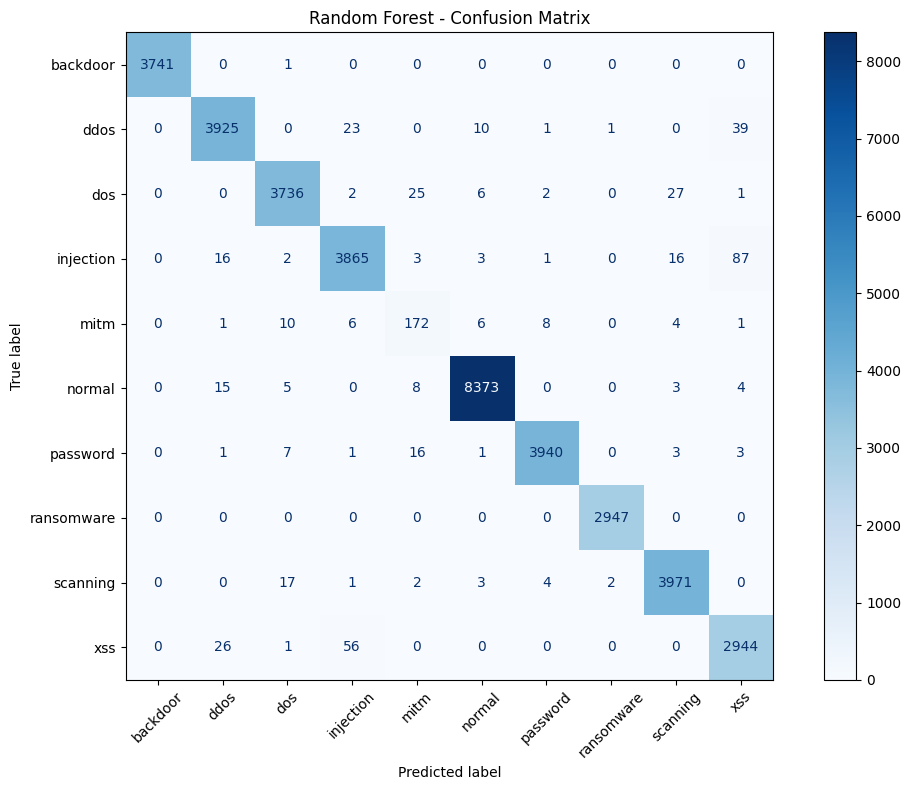

External Agreement,High-confidence Agreement,High-confidence Coverage,Confidence Threshold
56.30%,93.07%,41.57%,0.80


Malicious Events,Campaigns,Candidate Multi-stage,Non-progressive,Single-stage,Alert Reduction
"1,253,175","3,330",2,522,"2,806",99.73%


,Source IP,Destination IP,Attack Sequence,Stage Sequence,Risk Score,Risk Level,Mean Confidence
0,192.168.1.31,192.168.1.250,scanning → xss → password,Reconnaissance → Initial Access → Credential A...,65.08,HIGH,1.00
1,192.168.1.190,202.12.31.53,mitm → ddos,Credential/Network Access → Impact,56.29,HIGH,0.97


Predicted-label Support,GT Coverage,Jaccard Similarity,Ordered Support,Exact Match
16.66%,50.00%,16.66%,0,0


,predicted_attack_sequence,ground_truth_attack_sequence,predicted_label_support,ground_truth_label_coverage,label_jaccard,ordered_sequence_support,exact_sequence_match,validation_status,risk_score,risk_level
0,scanning → xss → password,scanning,33.33%,100.0%,33.33%,False,False,Partial Ground-Truth Support,65.08,HIGH
1,mitm → ddos,None,0.0%,0.0%,0.0%,False,False,No Ground-Truth Attack Support,56.29,HIGH



Final evaluation metrics saved:
/content/drive/MyDrive/AutoSOC_Project/AutoSOC_Final_Evaluation_Metrics.csv

FINAL EXPERIMENTAL RESULTS & EVALUATION COMPLETE ✅


In [ ]:
# ============================================================
# AUTOSOC - FINAL EXPERIMENTAL RESULTS & EVALUATION
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, HTML

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("=" * 100)
print("AUTOSOC - FINAL EXPERIMENTAL RESULTS AND EVALUATION")
print("=" * 100)


# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "y_test",
    "y_pred",
    "detected_events",
    "campaigns",
    "final_report"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Please run STEP 1 to STEP 5 first. "
        f"Missing variables: {missing_variables}"
    )


# ============================================================
# 1. STANDARD ML EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)


display(
    HTML(
        "<h3 style='color:#2F6BFF;'>1. Model Performance</h3>"
    )
)

model_performance = pd.DataFrame([{

    "Accuracy":
        f"{accuracy * 100:.2f}%",

    "Macro Precision":
        f"{macro_precision:.2f}",

    "Macro Recall":
        f"{macro_recall:.2f}",

    "Macro F1":
        f"{macro_f1:.2f}",

    "Weighted Precision":
        f"{weighted_precision:.2f}",

    "Weighted Recall":
        f"{weighted_recall:.2f}",

    "Weighted F1":
        f"{weighted_f1:.2f}"
}])

display(
    model_performance.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#173B57"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        }
    ])
)


# ============================================================
# 2. PER-CLASS PRECISION, RECALL AND F1
# ============================================================

display(
    HTML(
        "<h3 style='color:#2F6BFF;'>2. Per-Class Evaluation Metrics</h3>"
    )
)

class_report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(
    class_report
).transpose()

# Only actual attack/normal classes
class_names = [
    x
    for x in threat_model.classes_
    if x in class_report_df.index
]

class_metrics = class_report_df.loc[
    class_names,
    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
].copy()

class_metrics.columns = [
    "Precision",
    "Recall",
    "F1-score",
    "Support"
]

class_metrics["Precision"] = (
    class_metrics["Precision"]
    .round(3)
)

class_metrics["Recall"] = (
    class_metrics["Recall"]
    .round(3)
)

class_metrics["F1-score"] = (
    class_metrics["F1-score"]
    .round(3)
)

class_metrics["Support"] = (
    class_metrics["Support"]
    .astype(int)
)

display(
    class_metrics
)


# ============================================================
# 3. CONFUSION MATRIX
# ============================================================

display(
    HTML(
        "<h3 style='color:#2F6BFF;'>3. Confusion Matrix</h3>"
    )
)

fig, ax = plt.subplots(
    figsize=(11, 8)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=threat_model.classes_,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Random Forest - Confusion Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. EXTERNAL / CROSS-FILE EVALUATION
# ============================================================

display(
    HTML(
        "<h3 style='color:#2F6BFF;'>4. External Evaluation</h3>"
    )
)

external_results = pd.DataFrame([{

    "External Agreement":
        f"{external_accuracy * 100:.2f}%",

    "High-confidence Agreement":
        f"{high_conf_accuracy * 100:.2f}%",

    "High-confidence Coverage":
        f"{high_conf_coverage * 100:.2f}%",

    "Confidence Threshold":
        "0.80"
}])

display(
    external_results.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#173B57"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        }
    ])
)


# ============================================================
# 5. ATTACK CORRELATION RESULTS
# ============================================================

total_events = len(
    detected_events
)

total_campaigns = len(
    campaigns
)

multi_stage_count = int(
    (
        campaigns["campaign_type"]
        ==
        "Candidate Multi-stage"
    ).sum()
)

non_progressive_count = int(
    (
        campaigns["campaign_type"]
        ==
        "Correlated Multi-alert (Non-progressive)"
    ).sum()
)

single_stage_count = int(
    (
        campaigns["campaign_type"]
        ==
        "Single-stage"
    ).sum()
)

alert_reduction = (
    1
    -
    total_campaigns / total_events
) * 100


display(
    HTML(
        "<h3 style='color:#2F6BFF;'>5. Attack Correlation Results</h3>"
    )
)

correlation_results = pd.DataFrame([{

    "Malicious Events":
        f"{total_events:,}",

    "Campaigns":
        f"{total_campaigns:,}",

    "Candidate Multi-stage":
        multi_stage_count,

    "Non-progressive":
        non_progressive_count,

    "Single-stage":
        f"{single_stage_count:,}",

    "Alert Reduction":
        f"{alert_reduction:.2f}%"
}])

display(
    correlation_results.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#173B57"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        }
    ])
)


# ============================================================
# 6. CANDIDATE MULTI-STAGE CAMPAIGNS + RISK
# ============================================================

display(
    HTML(
        "<h3 style='color:#2F6BFF;'>6. Candidate Multi-stage Campaigns</h3>"
    )
)

candidate_results = final_report[
    final_report["campaign_type"]
    ==
    "Candidate Multi-stage"
][
    [
        "src_ip",
        "dst_ip",
        "attack_sequence",
        "stage_sequence",
        "risk_score",
        "risk_level",
        "mean_confidence"
    ]
].copy()

candidate_results.columns = [
    "Source IP",
    "Destination IP",
    "Attack Sequence",
    "Stage Sequence",
    "Risk Score",
    "Risk Level",
    "Mean Confidence"
]

if len(candidate_results) > 0:
    display(
        candidate_results
    )
else:
    print(
        "No candidate multi-stage campaign detected."
    )


# ============================================================
# 7. GROUND-TRUTH VALIDATION SUMMARY
# ============================================================

display(
    HTML(
        "<h3 style='color:#2F6BFF;'>7. Ground-Truth Validation</h3>"
    )
)

if (
    "campaign_validation" in globals()
    and
    len(campaign_validation) > 0
):

    avg_label_support = (
        campaign_validation[
            "predicted_label_support"
        ].mean()
        * 100
    )

    avg_gt_coverage = (
        campaign_validation[
            "ground_truth_label_coverage"
        ].mean()
        * 100
    )

    avg_jaccard = (
        campaign_validation[
            "label_jaccard"
        ].mean()
        * 100
    )

    ordered_support = int(
        campaign_validation[
            "ordered_sequence_support"
        ].sum()
    )

    exact_match = int(
        campaign_validation[
            "exact_sequence_match"
        ].sum()
    )

    validation_summary = pd.DataFrame([{

        "Predicted-label Support":
            f"{avg_label_support:.2f}%",

        "GT Coverage":
            f"{avg_gt_coverage:.2f}%",

        "Jaccard Similarity":
            f"{avg_jaccard:.2f}%",

        "Ordered Support":
            ordered_support,

        "Exact Match":
            exact_match
    }])

    display(
        validation_summary.style
        .hide(axis="index")
        .set_properties(**{
            "text-align": "center",
            "padding": "10px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#173B57"),
                    ("color", "white"),
                    ("text-align", "center"),
                    ("padding", "10px")
                ]
            }
        ])
    )


    # --------------------------------------------------------
    # DETAILED CAMPAIGN VALIDATION
    # --------------------------------------------------------

    display(
        HTML(
            "<h4 style='color:#2F6BFF;'>Campaign Validation Details</h4>"
        )
    )

    validation_details = campaign_validation[
        [
            "predicted_attack_sequence",
            "ground_truth_attack_sequence",
            "predicted_label_support",
            "ground_truth_label_coverage",
            "label_jaccard",
            "ordered_sequence_support",
            "exact_sequence_match",
            "validation_status",
            "risk_score",
            "risk_level"
        ]
    ].copy()

    validation_details[
        "predicted_label_support"
    ] = (
        validation_details[
            "predicted_label_support"
        ]
        * 100
    ).round(2).astype(str) + "%"

    validation_details[
        "ground_truth_label_coverage"
    ] = (
        validation_details[
            "ground_truth_label_coverage"
        ]
        * 100
    ).round(2).astype(str) + "%"

    validation_details[
        "label_jaccard"
    ] = (
        validation_details[
            "label_jaccard"
        ]
        * 100
    ).round(2).astype(str) + "%"

    display(
        validation_details
    )

else:

    print(
        "Ground-truth validation result is not available."
    )


# ============================================================
# 8. FINAL INTERPRETATION
# ============================================================

display(
    HTML(
        """
        <h3 style='color:#2F6BFF;'>8. Final Interpretation</h3>

        <div style="
            padding:15px;
            border-left:5px solid #2F6BFF;
            background:#f4f7ff;
            color:#222;
            line-height:1.7;
            font-size:14px;
        ">

        The Random Forest model achieved strong performance
        on the held-out test data.

        High-confidence filtering improved the reliability of
        predictions on the separate timestamped network files.

        The AutoSOC correlation engine reduced a large number
        of individual malicious-event alerts into a much smaller
        number of correlated campaigns.

        Candidate multi-stage campaigns were identified using
        source-target correlation, temporal reasoning, and
        strict forward attack-stage progression.

        Dedicated ground-truth files were used only after
        detection and correlation for evaluation. Therefore,
        candidate campaigns are not automatically treated as
        confirmed causal attack chains.

        </div>
        """
    )
)


# ============================================================
# 9. SAVE FINAL METRICS
# ============================================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Accuracy",

        "Macro Precision",
        "Macro Recall",
        "Macro F1",

        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",

        "External Agreement",
        "High-confidence Agreement",
        "High-confidence Coverage",

        "Malicious Events",
        "Total Campaigns",
        "Candidate Multi-stage Campaigns",
        "Alert Reduction",

        "Average GT Label Support",
        "Average GT Coverage",
        "Average Jaccard Similarity",

        "Ordered Sequence Support",
        "Exact Sequence Match"
    ],

    "Result": [

        f"{accuracy * 100:.2f}%",

        f"{macro_precision:.3f}",
        f"{macro_recall:.3f}",
        f"{macro_f1:.3f}",

        f"{weighted_precision:.3f}",
        f"{weighted_recall:.3f}",
        f"{weighted_f1:.3f}",

        f"{external_accuracy * 100:.2f}%",
        f"{high_conf_accuracy * 100:.2f}%",
        f"{high_conf_coverage * 100:.2f}%",

        f"{total_events:,}",
        f"{total_campaigns:,}",
        f"{multi_stage_count}",
        f"{alert_reduction:.2f}%",

        f"{avg_label_support:.2f}%",
        f"{avg_gt_coverage:.2f}%",
        f"{avg_jaccard:.2f}%",

        f"{ordered_support}",
        f"{exact_match}"
    ]
})


if "BASE_PATH" in globals():

    RESULT_PATH = os.path.join(
        BASE_PATH,
        "AutoSOC_Final_Evaluation_Metrics.csv"
    )

    final_metrics.to_csv(
        RESULT_PATH,
        index=False
    )

    print(
        "\nFinal evaluation metrics saved:"
    )

    print(
        RESULT_PATH
    )


print("\n" + "=" * 100)
print("FINAL EXPERIMENTAL RESULTS & EVALUATION COMPLETE ✅")
print("=" * 100)